# Inventory adjustments — fréquences, motifs et quantités atypiques
**G05 — contribution Merieme.** Analyse autonome de `inventory_adjustments_cleaned.csv`, sans jointure aux autres datasets.
Une ligne = un ajustement de stock. Le signe distingue une augmentation d'une diminution ; une quantité négative n'est pas une erreur.

**Méthodes reprises du groupe :** distributions, tableaux croisés, IQR/Z-score/Z modifié avec contexte métier. Les quantités sont comparées **par catégorie ET unité**. Complément : test conditionnel de pics mensuels avec correction BH.
Ce fichier ne possède qu'une mesure numérique indépendante pertinente (la quantité). On ne construit pas de fausse analyse multivariée en numérisant les identifiants ou les motifs ; IF/LOF ne sont donc pas imposés.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scipy.stats import binom, fisher_exact
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
import sklearn, scipy, sys

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'data/data_dictionary.csv').exists()), None)
assert ROOT is not None, "Lancer le notebook depuis le dépôt."
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.grid': True, 'grid.alpha': .2,
                     'font.size': 10, 'figure.dpi': 100})
pd.set_option('display.max_columns', 18)
pd.set_option('display.max_rows', 25)
print('Versions :', sys.version.split()[0], 'pandas', pd.__version__,
      'numpy', np.__version__, 'scikit-learn', sklearn.__version__, 'scipy', scipy.__version__)

def lecture(nom, domaine, cle):
    raw = pd.read_csv(ROOT / 'data' / domaine / (nom + '.csv'))
    path = ROOT / 'data' / domaine / 'cleaned' / (nom + '_cleaned.csv')
    clean = pd.read_csv(path)
    display(pd.DataFrame({'source': ['brut', 'nettoyé'],
                          'lignes': [len(raw), len(clean)],
                          'colonnes': [raw.shape[1], clean.shape[1]],
                          'doublons_exacts': [raw.duplicated().sum(), clean.duplicated().sum()],
                          'doublons_cle': [raw.duplicated(cle).sum(), clean.duplicated(cle).sum()]}))
    display(pd.DataFrame({'type': clean.dtypes.astype(str), 'manquants': clean.isna().sum()}))
    assert clean[cle].notna().all() and clean[cle].is_unique, "Clé primaire à vérifier."
    return raw, clean

def statistiques(data, cle, variables, groupes=(), min_n=8, haut_seul=False):
    """Comparaisons rétrospectives au sein de groupes homogènes ; aucune imputation."""
    records = []
    grouped = data.groupby(list(groupes), dropna=False, sort=True) if groupes else [('ensemble', data)]
    for key, group in grouped:
        if groupes:
            keys = key if isinstance(key, tuple) else (key,)
            label = '; '.join(f'{c}={v}' for c, v in zip(groupes, keys))
        else:
            label = 'ensemble'
        for variable in variables:
            x = pd.to_numeric(group[variable], errors='raise').replace([np.inf, -np.inf], np.nan)
            good = x.dropna()
            n = len(good)
            q1, q3 = good.quantile([.25, .75]) if n else (np.nan, np.nan)
            iqr, mean, sd = q3 - q1, good.mean(), good.std(ddof=1)
            med = good.median()
            mad = (good - med).abs().median()
            specs = [
                ('IQR', q1-1.5*iqr, q3+1.5*iqr, x, iqr, 'hors Q1−1.5×IQR ; Q3+1.5×IQR'),
                ('Z-score', mean-3*sd, mean+3*sd, (x-mean)/sd if sd > 0 else x*0+np.nan, sd, '|z| > 3'),
                ('Z-modifie', med-3.5*mad/.6745, med+3.5*mad/.6745,
                 .6745*(x-med)/mad if mad > 0 else x*0+np.nan, mad, '|z_mod| > 3.5'),
            ]
            for method, lo, hi, scores, spread, rule in specs:
                usable = n >= min_n and pd.notna(spread) and spread > 1e-12
                if haut_seul: lo = -np.inf; rule += ' (queue haute uniquement)'
                for idx in group.index:
                    available = bool(usable and pd.notna(x.loc[idx]))
                    flag = bool(available and (x.loc[idx] < lo or x.loc[idx] > hi))
                    records.append({
                        'observation': str(group.at[idx, cle]), 'groupe': label,
                        'variable': variable, 'methode': method, 'valeur': x.loc[idx],
                        'score': scores.loc[idx] if available else np.nan,
                        'borne_basse': lo if usable else np.nan, 'borne_haute': hi if usable else np.nan,
                        'n_reference': n, 'applicable': available, 'signalee': flag,
                        'regle': rule if usable else f'Non évalué : n < {min_n} ou dispersion nulle',
                        'interpretation': 'Valeur atypique dans ce groupe ; contrôle du contexte nécessaire, pas une erreur établie.'
                    })
    return pd.DataFrame(records)

def resume_tests(tests):
    display(tests.groupby(['variable', 'methode']).agg(
        evaluations=('applicable', 'sum'), signalees=('signalee', 'sum')).reset_index())
    skipped = tests.loc[~tests.applicable, ['groupe','variable','methode','regle']].drop_duplicates()
    if len(skipped):
        print('Cas non évalués (extrait) :'); display(skipped.head(12))

def bh(pvalues):
    """Benjamini–Hochberg : ajustement descriptif des comparaisons multiples."""
    pvalues = np.asarray(pvalues, dtype=float)
    result = np.full(len(pvalues), np.nan)
    good = np.flatnonzero(np.isfinite(pvalues))
    if len(good):
        order = good[np.argsort(pvalues[good])]
        adjusted = pvalues[order] * len(good) / np.arange(1, len(good)+1)
        result[order] = np.minimum.accumulate(adjusted[::-1])[::-1].clip(0,1)
    return result

def wilson(k, n, z=1.96):
    k, n = np.asarray(k, float), np.asarray(n, float)
    rate = k/n; den = 1+z*z/n
    center = (rate+z*z/(2*n))/den
    half = z*np.sqrt(rate*(1-rate)/n+z*z/(4*n*n))/den
    # Les bornes exactes k=0/k=n évitent les erreurs d'arrondi à 1e-17.
    low = np.where(k == 0, 0., np.clip(center-half, 0, 1))
    high = np.where(k == n, 1., np.clip(center+half, 0, 1))
    return low, high

def frequences(data, facility, date):
    """Panel entre premier et dernier mois observés, y compris les zéros enregistrés."""
    frames = []
    for name, g in data.groupby(facility):
        periods = g[date].dt.to_period('M')
        grid = pd.period_range(periods.min(), periods.max(), freq='M')
        counts = periods.value_counts().reindex(grid, fill_value=0).sort_index()
        out = pd.DataFrame({'etablissement':name, 'mois':grid.to_timestamp(), 'n':counts.values})
        # Bords exclus : premier/dernier mois d'activité observée potentiellement incomplets.
        out['interieur'] = (np.arange(len(out)) > 0) & (np.arange(len(out)) < len(out)-1)
        out['historique_12'] = out['n'].shift(1).rolling(12, min_periods=12).sum()
        past_complete = out['interieur'].shift(1).rolling(12, min_periods=12).sum().eq(12)
        out['eligible'] = out['interieur'] & past_complete
        out['p_pic'] = np.nan
        ix = out['eligible']
        # Sous un taux constant, conditionnellement au total, le mois testé représente 1/13 de l'exposition.
        total = (out.loc[ix,'historique_12']+out.loc[ix,'n']).astype(int)
        out.loc[ix,'p_pic'] = binom.sf(out.loc[ix,'n']-1, total, 1/13)
        out['observation'] = str(name)+'|'+out['mois'].dt.strftime('%Y-%m')
        frames.append(out)
    out = pd.concat(frames, ignore_index=True)
    out['q_pic'] = bh(out.p_pic)
    out['pic_BH'] = out.q_pic.lt(.05)
    return out

def test_pics(panel):
    result = pd.DataFrame({
        'observation': panel.observation, 'groupe':panel.etablissement,
        'variable':'nombre_mensuel', 'methode':'Binomial_conditionnel_BH',
        'valeur': panel.n, 'score':panel.q_pic,
        'historique_12':panel.historique_12, 'p_brut':panel.p_pic,
        'borne_basse':0., 'borne_haute':.05, 'n_reference':12,
        'applicable':panel.eligible, 'signalee':panel.pic_BH,
        'regle':'q_BH < 0.05 ; comparaison aux 12 mois précédents, bords exclus',
        'interpretation':"Pic exploratoire sous hypothèse de taux constant et couverture continue ; vérifier collecte et saisonnalité."
    })
    return result

def bilan(tests, nom, domaine):
    """Conserve toutes les détections avec leur méthode ; une ligne peut être signalée plusieurs fois."""
    tests = tests.copy()
    tests['echelle_seuil'] = np.where(tests.methode.isin(['Binomial_conditionnel_BH','Fisher_exact_BH','IF','LOF','LOF_k5']), 'score', 'valeur')
    flagged = tests.loc[tests.signalee].copy()
    output = ROOT / 'data' / domaine / 'syntheses'
    output.mkdir(parents=True, exist_ok=True)
    flagged.to_csv(output / (nom+'_anomalies.csv'), index=False)
    # Les bornes restent interprétables avec variable, méthode et effectif de référence.
    cols = ['groupe','variable','methode','borne_basse','borne_haute','n_reference','regle','echelle_seuil']
    tests[cols].drop_duplicates().to_csv(output / (nom+'_seuils.csv'), index=False)
    assert flagged.observation.notna().all()
    print(f'{len(flagged)} détections ; {flagged.observation.nunique()} identifiants distincts (unités d’analyse précisées dans le notebook).')
    display(flagged.head(20))
    return flagged


Versions : 3.9.6 pandas 2.3.3 numpy 2.0.2 scikit-learn 1.6.1 scipy 1.13.1


## 1. Audit et variables pertinentes
Les références optionnelles vides et le rôle d'approbation manquant restent conservés. Les écarts inter-tables du notebook précédent ne sont pas réévalués dans cette analyse par fichier.

In [2]:
raw,df=lecture('inventory_adjustments','logistics','adjustment_number')
df['adjustment_date']=pd.to_datetime(df.adjustment_date,errors='raise')
df['adjustment_quantity']=pd.to_numeric(df.adjustment_quantity,errors='raise')
assert df.adjustment_date.notna().all() and df.adjustment_quantity.notna().all()
df['magnitude']=df.adjustment_quantity.abs()
df['signe']=np.select([df.adjustment_quantity.lt(0),df.adjustment_quantity.gt(0)],['diminution','augmentation'],default='nul')
df['groupe_metier']=df.item_category+' / '+df.unit
df['month']=df.adjustment_date.dt.to_period('M')
print('Période :',df.adjustment_date.min().date(),'→',df.adjustment_date.max().date())
display(df.groupby(['item_category','unit']).agg(n=('adjustment_number','size'),
      negatif=('adjustment_quantity',lambda s:s.lt(0).sum()),positif=('adjustment_quantity',lambda s:s.gt(0).sum()),
      min=('adjustment_quantity','min'),mediane=('adjustment_quantity','median'),max=('adjustment_quantity','max')))
display(df.adjustment_status.value_counts(dropna=False))


,source,lignes,colonnes,doublons_exacts,doublons_cle
0,brut,140,11,0,0
1,nettoyé,140,11,0,0


,type,manquants
adjustment_number,object,0
facility_code,object,0
adjustment_date,object,0
item_category,object,0
adjustment_quantity,float64,0
unit,object,0
adjustment_reason,object,0
approved_by_role,object,1
related_receipt_number,object,117
related_shipment_number,object,103


Période : 2014-07-18 → 2025-06-30


,,n,negatif,positif,min,mediane,max
item_category,unit,,,,,,
agricultural_product,pallet,19,9,10,-7.91,1.000,7.24
biological_sample,sealed_lot,36,26,10,-7.25,-2.405,7.45
medical_consumables,case,51,41,10,-7.88,-2.070,7.41
monitoring_equipment,kit,20,8,12,-5.10,1.000,7.74
protective_equipment,case,14,5,9,-7.29,2.110,7.87


adjustment_status
posted            90
pending_review    25
approved          25
Name: count, dtype: int64

## 2. Motifs et directions des ajustements
Les graphiques de fréquence comptent des événements : ils peuvent réunir plusieurs unités. Les graphiques de quantité séparent systématiquement catégories et unités.

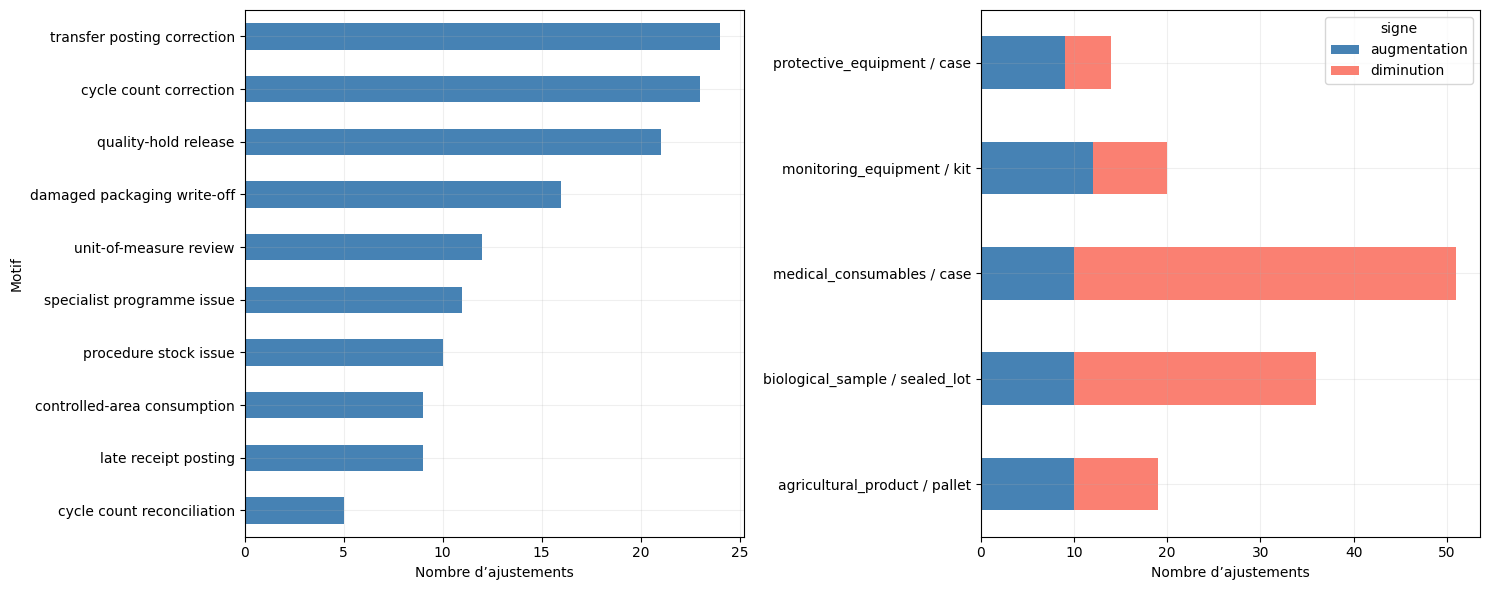

signe,augmentation,diminution
adjustment_reason,,
controlled-area consumption,0,9
cycle count correction,12,11
cycle count reconciliation,0,5
damaged packaging write-off,9,7
late receipt posting,8,1
procedure stock issue,0,10
quality-hold release,10,11
specialist programme issue,0,11
transfer posting correction,8,16


adjustment_status,approved,pending_review,posted
adjustment_reason,,,
controlled-area consumption,0,0,9
cycle count correction,5,8,10
cycle count reconciliation,0,0,5
damaged packaging write-off,6,4,6
late receipt posting,3,2,4
procedure stock issue,0,0,10
quality-hold release,4,4,13
specialist programme issue,0,0,11
transfer posting correction,4,4,16


**Lecture :** un motif associé aux deux signes peut décrire des corrections de sens opposés. Sans convention comptable explicite, on ne transforme pas un signe jugé surprenant en erreur certaine.

In [3]:
fig,axes=plt.subplots(1,2,figsize=(15,6))
df.adjustment_reason.value_counts().sort_values().plot.barh(ax=axes[0],color='steelblue')
axes[0].set_xlabel('Nombre d’ajustements');axes[0].set_ylabel('Motif')
pd.crosstab(df.groupe_metier,df.signe).plot.barh(stacked=True,ax=axes[1],color=['steelblue','salmon','grey'][:df.signe.nunique()])
axes[1].set_xlabel('Nombre d’ajustements');axes[1].set_ylabel('')
fig.tight_layout();plt.show()
motifs=pd.crosstab(df.adjustment_reason,df.signe)
display(motifs)
display(pd.crosstab(df.adjustment_reason,df.adjustment_status))
display(Markdown("**Lecture :** un motif associé aux deux signes peut décrire des corrections de sens opposés. "
                "Sans convention comptable explicite, on ne transforme pas un signe jugé surprenant en erreur certaine."))


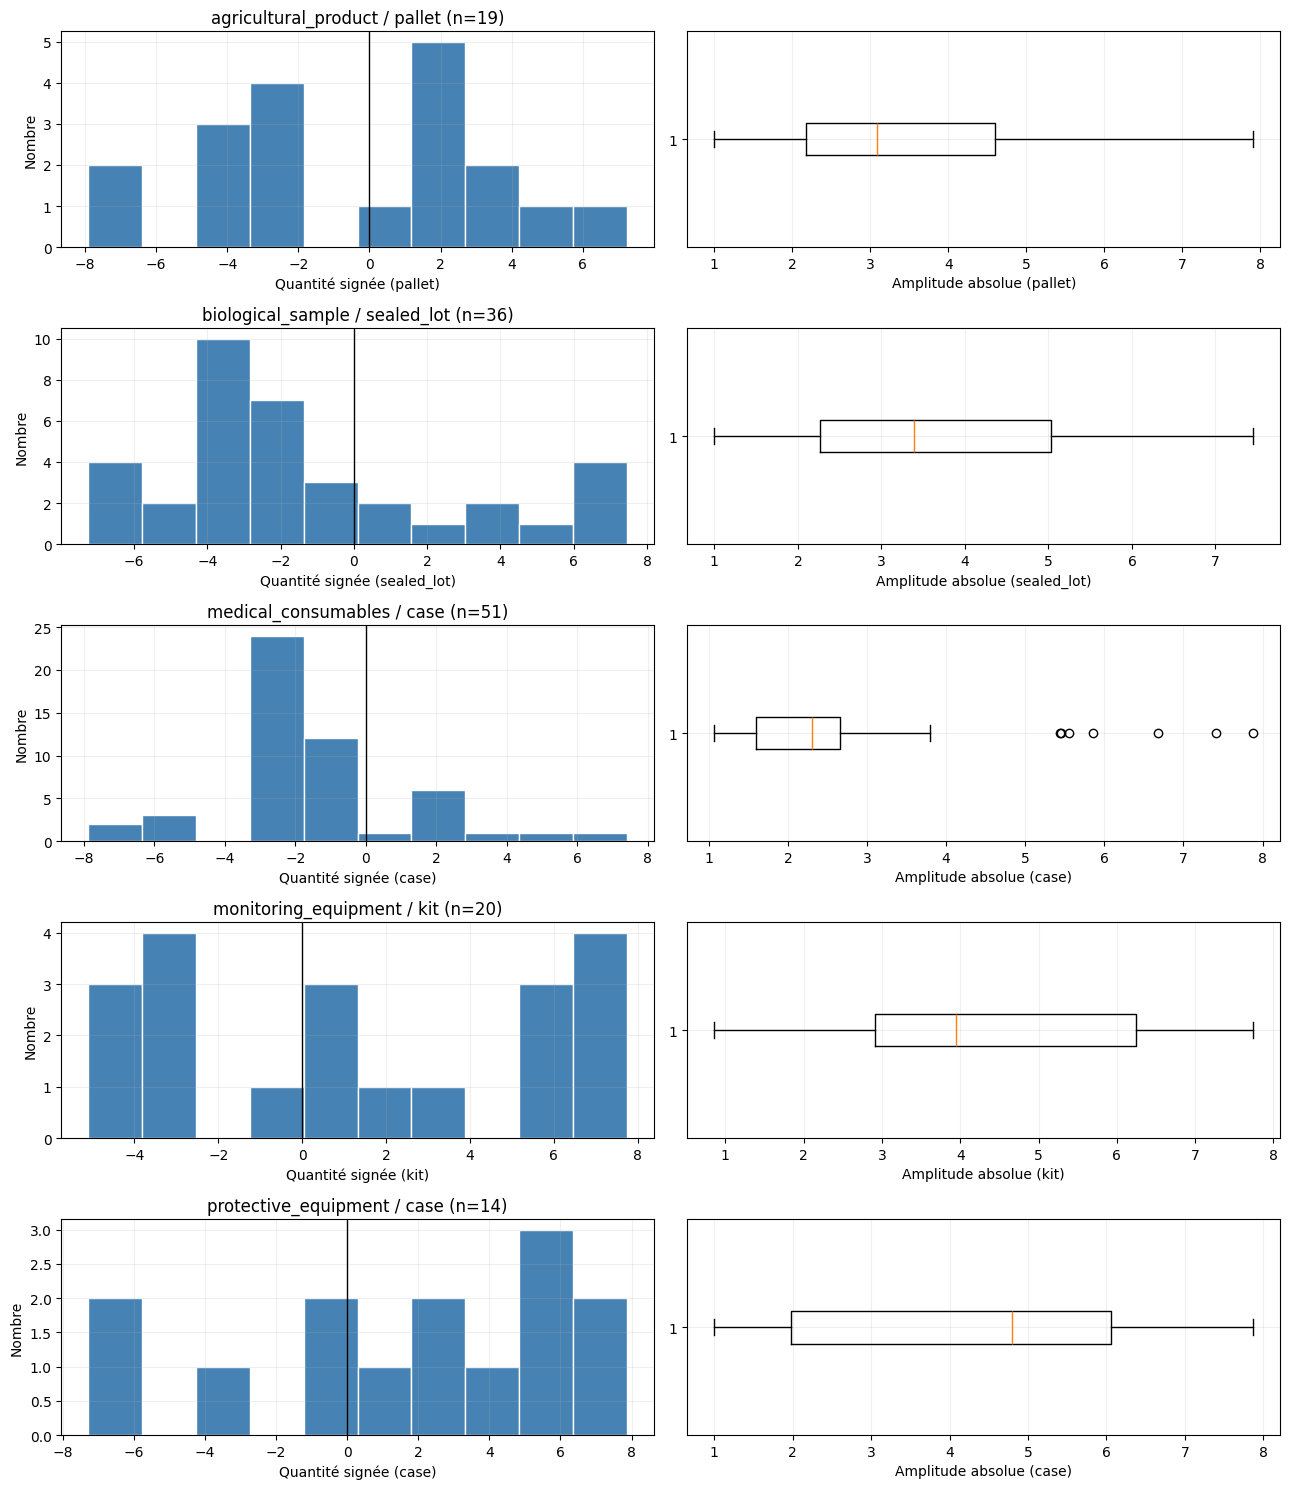

n   total  mediane  \
item_category        unit       signe                               
agricultural_product pallet     augmentation  10   29.82    2.420   
                                diminution     9  -38.34   -3.530   
biological_sample    sealed_lot augmentation  10   43.40    4.635   
                                diminution    26  -92.51   -3.250   
medical_consumables  case       augmentation  10   28.55    1.925   
                                diminution    41 -107.52   -2.310   
monitoring_equipment kit        augmentation  12   57.06    6.070   
                                diminution     8  -28.07   -3.405   
protective_equipment case       augmentation   9   41.76    5.630   
                                diminution     5  -17.99   -2.900   

                                              amplitude_max  
item_category        unit       signe                        
agricultural_product pallet     augmentation           7.24  
                                diminution             7.91  
biological_sample    sealed_lot augmentation           7.45  
                                diminution             7.25  
medical_consumables  case       augmentation           7.41  
                                diminution             7.88  
monitoring_equipment kit        augmentation           7.74  
                                diminution             5.10  
protective_equipment case       augmentation           7.87  
                                diminution             7.29

In [4]:
groups=list(df.groupby(['item_category','unit']))
fig,axes=plt.subplots(len(groups),2,figsize=(13,3*len(groups)))
for row,((category,unit),g) in enumerate(groups):
    axes[row,0].hist(g.adjustment_quantity,bins=10,color='steelblue',edgecolor='white')
    axes[row,0].axvline(0,c='black',lw=1)
    axes[row,0].set_title(f'{category} / {unit} (n={len(g)})')
    axes[row,0].set_xlabel(f'Quantité signée ({unit})');axes[row,0].set_ylabel('Nombre')
    axes[row,1].boxplot(g.magnitude,vert=False)
    axes[row,1].set_xlabel(f'Amplitude absolue ({unit})')
fig.tight_layout();plt.show()
# Bilans séparés : aucune somme globale d'unités incompatibles.
balance=df.groupby(['item_category','unit','signe']).agg(
    n=('adjustment_number','size'),total=('adjustment_quantity','sum'),
    mediane=('adjustment_quantity','median'),amplitude_max=('magnitude','max'))
display(balance)


### Règles de lecture communes
IQR : bornes Q1 − 1,5×IQR et Q3 + 1,5×IQR ; Z-score : |z| > 3 ; Z modifié : 0,6745×(x−médiane)/MAD, seuil 3,5.
Ces seuils exploratoires viennent des notebooks du groupe, pas d'une vérité terrain.
Les groupes de moins de 8 observations et les dispersions nulles sont déclarés **non évaluables** : pas de division par zéro, ni de classement automatique de toute valeur non nulle comme anomalie.
Les comparaisons utilisent des groupes explicites ; elles sont rétrospectives et n'estiment pas une causalité.
Les résultats complets signalés et les seuils sont exportés uniquement dans `syntheses/`. Les fichiers bruts et nettoyés ne sont pas modifiés.


## 3. Quantités exceptionnellement importantes
Deux lectures complémentaires : quantité signée (deux queues) et amplitude absolue (deux queues, dont les très faibles corrections peuvent aussi être rares).
Les groupes métier de 14 à 51 événements restent petits. Les distributions mélangeant augmentations et diminutions peuvent masquer des signaux.
Une vérification secondaire sépare les signes quand n≥8, mais ne transforme pas les petits groupes en preuves.

In [5]:
tests_qty=statistiques(df,'adjustment_number',['adjustment_quantity','magnitude'],['item_category','unit'])
resume_tests(tests_qty)
signed_checks=statistiques(df,'adjustment_number',['magnitude'],['item_category','unit','signe'])
# Cette deuxième lecture est explicitement identifiée dans le registre.
signed_checks['methode']=signed_checks.methode+' (par signe)'
resume_tests(signed_checks)
quantity_ids=set(tests_qty.loc[tests_qty.signalee,'observation']) | set(signed_checks.loc[signed_checks.signalee,'observation'])
display(df.loc[df.adjustment_number.isin(quantity_ids),[
    'adjustment_number','adjustment_date','facility_code','item_category','unit',
    'adjustment_quantity','adjustment_reason','adjustment_status']].sort_values('adjustment_date'))
# Les maxima sont une liste de lecture, pas une liste d'anomalies.
extremes=df.sort_values('magnitude',ascending=False).groupby(['item_category','unit']).head(2)
display(extremes[['adjustment_number','item_category','unit','adjustment_quantity','adjustment_reason']])
display(Markdown(f"**Lecture calculée :** {len(quantity_ids)} ajustements signalés sur les quantités dans "
                "au moins une comparaison. Les plus grandes amplitudes sont également affichées pour lecture manuelle ; "
                "un maximum n'est pas automatiquement une anomalie."))

large_magnitude=tests_qty.loc[tests_qty.variable.eq('magnitude') & tests_qty.signalee & tests_qty.valeur.gt(tests_qty.borne_haute), 'observation'].unique()
display(Markdown(f'**Amplitudes importantes dans le groupe catégorie/unité :** {len(large_magnitude)} ajustements. Les détections sur la quantité signée incluent aussi des augmentations rares au milieu de diminutions habituelles ; elles ne mesurent pas toutes une grande amplitude.'))
display(df.loc[df.adjustment_number.isin(large_magnitude), ['adjustment_number','item_category','unit','adjustment_quantity','adjustment_reason']])


,variable,methode,evaluations,signalees
0,adjustment_quantity,IQR,140,15
1,adjustment_quantity,Z-modifie,140,19
2,adjustment_quantity,Z-score,140,1
3,magnitude,IQR,140,7
4,magnitude,Z-modifie,140,7
5,magnitude,Z-score,140,1


,variable,methode,evaluations,signalees
0,magnitude,IQR (par signe),135,10
1,magnitude,Z-modifie (par signe),135,8
2,magnitude,Z-score (par signe),135,1


Cas non évalués (extrait) :


,groupe,variable,methode,regle
405,item_category=protective_equipment; unit=case;...,magnitude,IQR (par signe),Non évalué : n < 8 ou dispersion nulle
410,item_category=protective_equipment; unit=case;...,magnitude,Z-score (par signe),Non évalué : n < 8 ou dispersion nulle
415,item_category=protective_equipment; unit=case;...,magnitude,Z-modifie (par signe),Non évalué : n < 8 ou dispersion nulle


,adjustment_number,adjustment_date,facility_code,item_category,unit,adjustment_quantity,adjustment_reason,adjustment_status
3,ADJ-2016-00004,2016-01-20,FCL-1007,biological_sample,sealed_lot,6.52,late receipt posting,pending_review
5,ADJ-2016-00006,2016-06-12,FCL-1004,medical_consumables,case,1.48,damaged packaging write-off,posted
15,ADJ-2018-00016,2018-02-22,FCL-1029,biological_sample,sealed_lot,-7.25,cycle count correction,posted
17,ADJ-2018-00018,2018-02-26,FCL-1029,biological_sample,sealed_lot,6.04,cycle count correction,approved
29,ADJ-2019-00030,2019-01-11,FCL-1015,biological_sample,sealed_lot,6.00,late receipt posting,approved
31,ADJ-2019-00032,2019-01-24,FCL-1022,medical_consumables,case,-5.86,cycle count correction,pending_review
47,ADJ-2019-00048,2019-11-12,FCL-1003,medical_consumables,case,2.25,cycle count correction,approved
48,ADJ-2019-00049,2019-11-21,FCL-1003,medical_consumables,case,-5.45,quality-hold release,posted
61,ADJ-2020-00062,2020-06-19,FCL-1008,biological_sample,sealed_lot,7.45,cycle count correction,pending_review
67,ADJ-2021-00068,2021-03-20,FCL-1017,medical_consumables,case,-5.44,unit-of-measure review,posted


,adjustment_number,item_category,unit,adjustment_quantity,adjustment_reason
43,ADJ-2019-00044,agricultural_product,pallet,-7.91,transfer posting correction
96,ADJ-2022-00097,medical_consumables,case,-7.88,cycle count correction
108,ADJ-2023-00109,protective_equipment,case,7.87,quality-hold release
82,ADJ-2022-00083,monitoring_equipment,kit,7.74,transfer posting correction
35,ADJ-2019-00036,agricultural_product,pallet,-7.61,transfer posting correction
19,ADJ-2018-00020,monitoring_equipment,kit,7.58,transfer posting correction
61,ADJ-2020-00062,biological_sample,sealed_lot,7.45,cycle count correction
92,ADJ-2022-00093,medical_consumables,case,7.41,late receipt posting
130,ADJ-2025-00131,protective_equipment,case,-7.29,transfer posting correction
15,ADJ-2018-00016,biological_sample,sealed_lot,-7.25,cycle count correction


**Lecture calculée :** 23 ajustements signalés sur les quantités dans au moins une comparaison. Les plus grandes amplitudes sont également affichées pour lecture manuelle ; un maximum n'est pas automatiquement une anomalie.

**Amplitudes importantes dans le groupe catégorie/unité :** 7 ajustements. Les détections sur la quantité signée incluent aussi des augmentations rares au milieu de diminutions habituelles ; elles ne mesurent pas toutes une grande amplitude.

,adjustment_number,item_category,unit,adjustment_quantity,adjustment_reason
31,ADJ-2019-00032,medical_consumables,case,-5.86,cycle count correction
48,ADJ-2019-00049,medical_consumables,case,-5.45,quality-hold release
67,ADJ-2021-00068,medical_consumables,case,-5.44,unit-of-measure review
92,ADJ-2022-00093,medical_consumables,case,7.41,late receipt posting
96,ADJ-2022-00097,medical_consumables,case,-7.88,cycle count correction
115,ADJ-2024-00116,medical_consumables,case,-6.68,damaged packaging write-off
131,ADJ-2025-00132,medical_consumables,case,5.55,quality-hold release


## 4. Fréquences par établissement et période
Les mois internes sans événement enregistré sont inclus sous l'hypothèse de couverture continue. Les bords de chaque historique observé sont exclus des tests.
La faible densité d'événements rend souvent IQR et MAD nuls. Le Z-score peut alors signaler un événement isolé simplement parce que les autres mois sont à zéro : il ne suffit pas à établir une fréquence anormale.
Le test complémentaire compare le compte courant aux 12 mois précédents : Binomiale(total des 13 mois, 1/13), puis BH sur les fenêtres testées.

,variable,methode,evaluations,signalees
0,n,IQR,0,0
1,n,Z-modifie,0,0
2,n,Z-score,1342,31


Cas non évalués (extrait) :


,groupe,variable,methode,regle
0,etablissement=FCL-1001,n,IQR,Non évalué : n < 12 ou dispersion nulle
152,etablissement=FCL-1001,n,Z-modifie,Non évalué : n < 12 ou dispersion nulle
228,etablissement=FCL-1003,n,IQR,Non évalué : n < 12 ou dispersion nulle
358,etablissement=FCL-1003,n,Z-modifie,Non évalué : n < 12 ou dispersion nulle
423,etablissement=FCL-1004,n,IQR,Non évalué : n < 12 ou dispersion nulle
611,etablissement=FCL-1004,n,Z-modifie,Non évalué : n < 12 ou dispersion nulle
705,etablissement=FCL-1005,n,IQR,Non évalué : n < 12 ou dispersion nulle
775,etablissement=FCL-1005,n,Z-modifie,Non évalué : n < 12 ou dispersion nulle
810,etablissement=FCL-1006,n,IQR,Non évalué : n < 12 ou dispersion nulle
871,etablissement=FCL-1006,n,Z-score,Non évalué : n < 12 ou dispersion nulle


Fenêtres évaluables : 1437
Pics p<0.05 avant BH : 4
Pics q<0.05 après BH : 0


,observation,n,historique_12,p_pic,q_pic,pic_BH
13,FCL-1001|2019-04,0,0.0,1.000000,1.0,False
14,FCL-1001|2019-05,0,0.0,1.000000,1.0,False
15,FCL-1001|2019-06,0,0.0,1.000000,1.0,False
16,FCL-1001|2019-07,0,0.0,1.000000,1.0,False
17,FCL-1001|2019-08,1,0.0,0.076923,1.0,False
18,FCL-1001|2019-09,1,1.0,0.147929,1.0,False
19,FCL-1001|2019-10,0,2.0,1.000000,1.0,False
20,FCL-1001|2019-11,0,2.0,1.000000,1.0,False
21,FCL-1001|2019-12,0,2.0,1.000000,1.0,False
22,FCL-1001|2020-01,0,2.0,1.000000,1.0,False


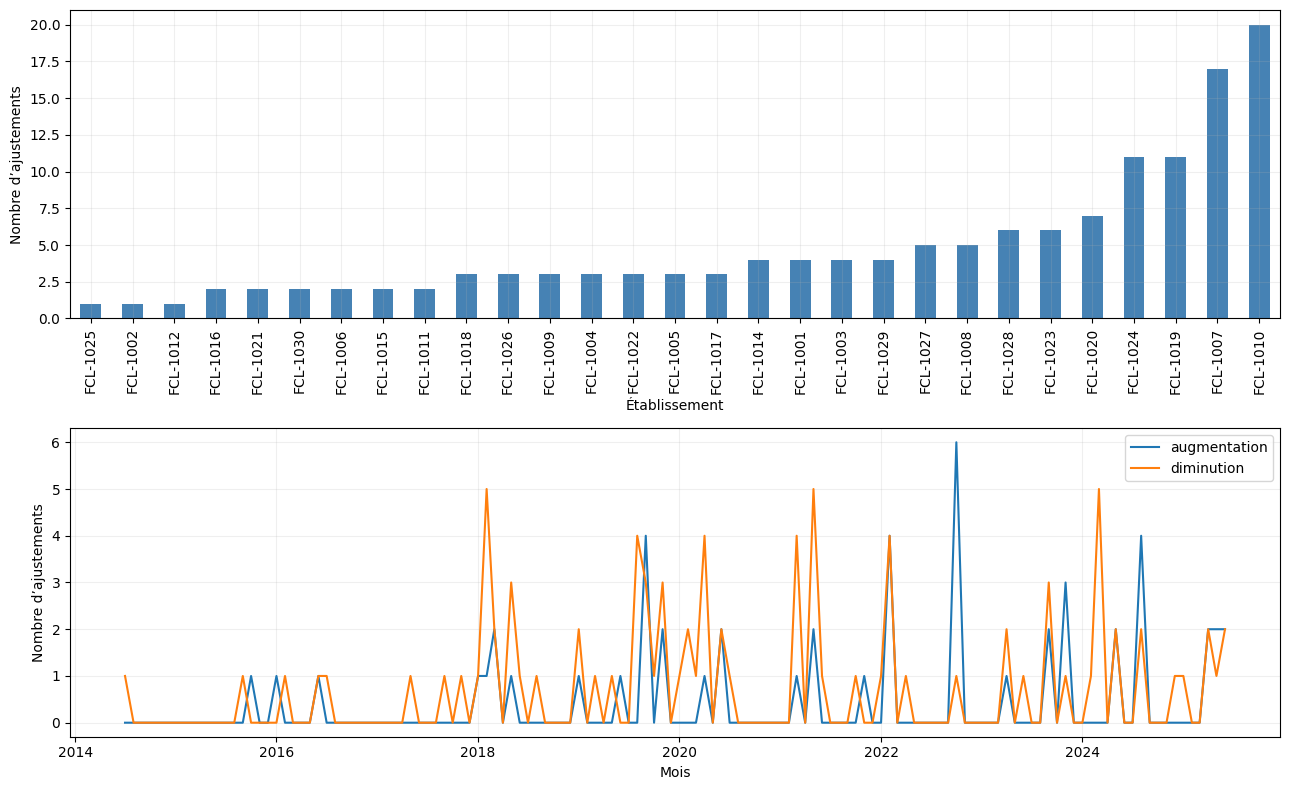

**Lecture :** les fréquences dépendent des pratiques de saisie et de la durée couverte. Aucun taux par quantité de stock ou par réception ne peut être déduit de ce seul fichier.

In [6]:
facility_counts=df.facility_code.value_counts()
panel=frequences(df,'facility_code','adjustment_date')
freq_stats=statistiques(panel.loc[panel.interieur],'observation',['n'],['etablissement'],min_n=12,haut_seul=True)
freq_tests=test_pics(panel)
resume_tests(freq_stats)
print('Fenêtres évaluables :',panel.eligible.sum())
print('Pics p<0.05 avant BH :',panel.p_pic.lt(.05).sum())
print('Pics q<0.05 après BH :',panel.pic_BH.sum())
display(panel.loc[panel.eligible].nsmallest(12,'q_pic')[
    ['observation','n','historique_12','p_pic','q_pic','pic_BH']])
fig,axes=plt.subplots(2,1,figsize=(13,8))
facility_counts.sort_values().plot.bar(ax=axes[0],color='steelblue')
axes[0].set_ylabel('Nombre d’ajustements');axes[0].set_xlabel('Établissement')
months=pd.period_range(df.month.min(),df.month.max(),freq='M')
for sign,g in df.groupby('signe'):
    counts=g.month.value_counts().reindex(months,fill_value=0)
    axes[1].plot(months.to_timestamp(),counts,label=sign)
axes[1].set_xlabel('Mois');axes[1].set_ylabel('Nombre d’ajustements');axes[1].legend()
fig.tight_layout();plt.show()
display(Markdown("**Lecture :** les fréquences dépendent des pratiques de saisie et de la durée couverte. "
                "Aucun taux par quantité de stock ou par réception ne peut être déduit de ce seul fichier."))


## 5. Registre, bilan et limites
Les identifiants `ADJ-…` désignent des lignes individuelles. Les identifiants `FCL-…|AAAA-MM` désignent des comptes mensuels, reliés aux ajustements sources. Les deux niveaux ne sont pas additionnés comme s'il s'agissait de mêmes observations.

In [7]:
quantity_tests=pd.concat([tests_qty,signed_checks],ignore_index=True)
quantity_tests=quantity_tests.merge(
    df[['adjustment_number','adjustment_date','facility_code','adjustment_quantity','item_category','unit','adjustment_reason','signe']],
    left_on='observation',right_on='adjustment_number',how='left',validate='many_to_one')
quantity_tests['observations_sources']=quantity_tests.observation
monthly_tests=pd.concat([freq_stats,freq_tests],ignore_index=True)
members=df.groupby(['facility_code','month']).adjustment_number.agg(lambda x:'; '.join(x))
source_map={row.observation: members.get((row.etablissement,pd.Period(row.mois,freq='M')),
                                         '[aucun ajustement enregistré]')
            for row in panel.itertuples()}
monthly_tests['observations_sources']=monthly_tests.observation.map(source_map)
all_tests=pd.concat([quantity_tests,monthly_tests],ignore_index=True)
all_tests.loc[all_tests.variable.eq('adjustment_quantity'),'interpretation']='Quantité signée rare dans la catégorie/unité ; peut refléter une augmentation légitime dans un groupe dominé par les diminutions.'
all_tests.loc[all_tests.variable.eq('magnitude'),'interpretation']='Amplitude rare dans le groupe indiqué ; vérifier si elle est haute ou basse et la taille du stock concerné.'
register=bilan(all_tests,'inventory_adjustments','logistics')
summary={
    'n':len(df),'negative':int(df.adjustment_quantity.lt(0).sum()),
    'positive':int(df.adjustment_quantity.gt(0).sum()),'quantity_flags':len(quantity_ids),
    'large_magnitude':len(large_magnitude), 'quantity_ids':sorted(quantity_ids),'conditional_peaks':int(panel.pic_BH.sum()),
    'stats_months':int(freq_stats.loc[freq_stats.signalee,'observation'].nunique()),
    'top_facility':facility_counts.index[0],'top_facility_count':int(facility_counts.iloc[0])
}
display(Markdown(f"**Bilan calculé :** {len(df)} ajustements, dont {summary['negative']} négatifs et "
                f"{summary['positive']} positifs. {summary['quantity_flags']} ajustements signalés sur les quantités ; "
                f"{summary['stats_months']} mois par IQR/Z ; {summary['conditional_peaks']} pics de fréquence après BH. "
                f"{summary['top_facility']} a le plus d'événements enregistrés ({summary['top_facility_count']}). "
                "Ce volume ne prouve pas un dysfonctionnement : on ignore ici son activité totale."))
assert panel.n.sum()==len(df)
assert df.adjustment_number.is_unique and len(df)==len(raw)
assert panel.loc[panel.pic_BH,'eligible'].all()


100 détections ; 54 identifiants distincts (unités d’analyse précisées dans le notebook).


,observation,groupe,variable,methode,valeur,score,borne_basse,borne_haute,n_reference,...,adjustment_quantity,item_category,unit,adjustment_reason,signe,observations_sources,historique_12,p_brut,echelle_seuil
186,ADJ-2016-00004,item_category=biological_sample; unit=sealed_lot,adjustment_quantity,Z-modifie,6.52,3.798052,-10.629611,5.819611,36,...,6.52,biological_sample,sealed_lot,late receipt posting,augmentation,ADJ-2016-00004,NaN,NaN,valeur
188,ADJ-2018-00018,item_category=biological_sample; unit=sealed_lot,adjustment_quantity,Z-modifie,6.04,3.593787,-10.629611,5.819611,36,...,6.04,biological_sample,sealed_lot,cycle count correction,augmentation,ADJ-2018-00018,NaN,NaN,valeur
193,ADJ-2019-00030,item_category=biological_sample; unit=sealed_lot,adjustment_quantity,Z-modifie,6.00,3.576765,-10.629611,5.819611,36,...,6.00,biological_sample,sealed_lot,late receipt posting,augmentation,ADJ-2019-00030,NaN,NaN,valeur
203,ADJ-2020-00062,item_category=biological_sample; unit=sealed_lot,adjustment_quantity,Z-modifie,7.45,4.193815,-10.629611,5.819611,36,...,7.45,biological_sample,sealed_lot,cycle count correction,augmentation,ADJ-2020-00062,NaN,NaN,valeur
333,ADJ-2016-00006,item_category=medical_consumables; unit=case,adjustment_quantity,IQR,1.48,1.480000,-4.327500,0.372500,51,...,1.48,medical_consumables,case,damaged packaging write-off,augmentation,ADJ-2016-00006,NaN,NaN,valeur
343,ADJ-2019-00032,item_category=medical_consumables; unit=case,adjustment_quantity,IQR,-5.86,-5.860000,-4.327500,0.372500,51,...,-5.86,medical_consumables,case,cycle count correction,diminution,ADJ-2019-00032,NaN,NaN,valeur
348,ADJ-2019-00048,item_category=medical_consumables; unit=case,adjustment_quantity,IQR,2.25,2.250000,-4.327500,0.372500,51,...,2.25,medical_consumables,case,cycle count correction,augmentation,ADJ-2019-00048,NaN,NaN,valeur
349,ADJ-2019-00049,item_category=medical_consumables; unit=case,adjustment_quantity,IQR,-5.45,-5.450000,-4.327500,0.372500,51,...,-5.45,medical_consumables,case,quality-hold release,diminution,ADJ-2019-00049,NaN,NaN,valeur
354,ADJ-2021-00068,item_category=medical_consumables; unit=case,adjustment_quantity,IQR,-5.44,-5.440000,-4.327500,0.372500,51,...,-5.44,medical_consumables,case,unit-of-measure review,diminution,ADJ-2021-00068,NaN,NaN,valeur
361,ADJ-2022-00086,item_category=medical_consumables; unit=case,adjustment_quantity,IQR,1.07,1.070000,-4.327500,0.372500,51,...,1.07,medical_consumables,case,quality-hold release,augmentation,ADJ-2022-00086,NaN,NaN,valeur


**Bilan calculé :** 140 ajustements, dont 89 négatifs et 51 positifs. 23 ajustements signalés sur les quantités ; 31 mois par IQR/Z ; 0 pics de fréquence après BH. FCL-1010 a le plus d'événements enregistrés (20). Ce volume ne prouve pas un dysfonctionnement : on ignore ici son activité totale.

## 6. Vérification complémentaire M2 — références documentaires des ajustements

Le fichier fournit deux références facultatives : une réception et/ou une expédition. Nous vérifions séparément leur existence, puis les dates associées. Une référence pointant vers un événement enregistré **après** la date de l'ajustement est inhabituelle si elle prétend justifier cet ajustement, mais peut aussi correspondre à une liaison administrative ajoutée ultérieurement. Ce contrôle descriptif n'altère aucune ligne ; il ne compare pas ici les montants ou les unités, et ne qualifie aucune personne de responsable.


In [8]:
receipts=pd.read_csv(ROOT/'data/logistics/cleaned/goods_receipts_cleaned.csv',
                      usecols=['receipt_number','receipt_date'])
shipments=pd.read_csv(ROOT/'data/logistics/cleaned/shipments_clean.csv',
                       usecols=['shipment_number','dispatch_time'])
receipts['receipt_date']=pd.to_datetime(receipts.receipt_date,errors='raise')
shipments['dispatch_time']=pd.to_datetime(shipments.dispatch_time,errors='raise')
assert receipts.receipt_number.is_unique
# Une expédition peut avoir plusieurs segments : premier départ enregistré par expédition.
first_departure=shipments.groupby('shipment_number',as_index=False).dispatch_time.min()
refs=df[['adjustment_number','adjustment_date','facility_code','adjustment_reason',
         'related_receipt_number','related_shipment_number']].copy()
refs=refs.merge(receipts,left_on='related_receipt_number',right_on='receipt_number',
                how='left',validate='many_to_one')
refs=refs.merge(first_departure,left_on='related_shipment_number',right_on='shipment_number',
                how='left',validate='many_to_one')
assert len(refs)==len(df)
for source,target,date in [('réception','related_receipt_number','receipt_date'),
                           ('expédition','related_shipment_number','dispatch_time')]:
    has_ref=refs[target].notna()
    known=refs[date].notna()
    future=has_ref & known & (refs[date].dt.normalize()>refs.adjustment_date.dt.normalize())
    refs['future_'+date]=future
    print(f'{source} : {has_ref.sum()} références ; {(has_ref & ~known).sum()} introuvables ; {future.sum()} événements datés après l’ajustement')
print('Ajustements ayant au moins une référence future :',
      int(refs[['future_receipt_date','future_dispatch_time']].any(axis=1).sum()))
display(refs.loc[refs[['future_receipt_date','future_dispatch_time']].any(axis=1),
 ['adjustment_number','adjustment_date','related_receipt_number','receipt_date',
  'related_shipment_number','dispatch_time']].head(20))
print('Ces écarts exigent de clarifier le sens métier des références ; ils ne prouvent pas une manipulation.')


réception : 23 références ; 0 introuvables ; 11 événements datés après l’ajustement
expédition : 37 références ; 0 introuvables ; 13 événements datés après l’ajustement
Ajustements ayant au moins une référence future : 21
   adjustment_number adjustment_date related_receipt_number receipt_date  \
2     ADJ-2015-00003      2015-10-30         RCV-2022-00361   2022-08-25   
5     ADJ-2016-00006      2016-06-12         RCV-2024-00527   2024-07-04   
13    ADJ-2018-00014      2018-02-18         RCV-2023-00414   2023-04-16   
15    ADJ-2018-00016      2018-02-22         RCV-2024-00522   2024-07-06   
16    ADJ-2018-00017      2018-02-23         RCV-2017-00054   2017-02-17   
17    ADJ-2018-00018      2018-02-26         RCV-2023-00446   2023-09-15   
35    ADJ-2019-00036      2019-08-13         RCV-2022-00342   2022-03-26   
36    ADJ-2019-00037      2019-08-18         RCV-2020-00186   2020-02-18   
37    ADJ-2019-00038      2019-08-19         RCV-2024-00497   2024-05-02   
40    ADJ-2019-000

### Limites et vérifications manuelles
Les quantités n'ont pas de dénominateur de stock disponible dans ce fichier : on ne mesure pas leur importance relative au stock.
Les motifs proches restent distincts ; aucun regroupement sémantique arbitraire. Les références non renseignées restent absentes.
Les modèles de comptage supposent une couverture continue, des expositions mensuelles comparables et un taux local stable ; hypothèses à confirmer.
Les seuils univariés ne sont pas corrigés pour comparaisons multiples et les groupes sont petits. IQR/MAD nuls et n<8 sont documentés, pas remplacés par des détections forcées.
Aucune méthode multivariée n'est ajoutée pour satisfaire une liste d'algorithmes : les identifiants ne sont pas des variables numériques et quantité/amplitude sont redondantes.
**Assistance IA :** code et rédaction préparés avec assistance ; interprétations à valider par le groupe.